# 01 Metrics, binary task and significance tests

Reads the predictions that the modelling notebooks exported and produces:

1. one table with every metric of every run (macro F1, MCC, AUC-PR, balanced accuracy,
   per class F1, and the per source majority vote),
2. the binary against three class comparison for **H2**,
3. confidence intervals with a **bootstrap over source addresses**,
4. significance tests for **H1** (distance), **H3** (packet against grouped split),
   **H4** (in domain against transfer) and the model comparison,
5. optionally the variability over the two hour blocks (leave one block out, retrains the
   random forest).

Why a bootstrap over sources and not over packets: the packets of one address are strongly
correlated, so treating them as independent samples gives intervals that are far too narrow
and p values that are far too small. Resampling whole addresses respects that structure.
McNemar is reported as well, because it is the textbook paired test, but it treats packets as
independent and is therefore optimistic.

Sections 1 to 4 need no training and take seconds to a few minutes.

In [1]:
import sys, pathlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append(str(pathlib.Path.cwd()))  # the notebooks live in code/analysis
import analysis_utils as au
importlib.reload(au)

RESULTS = pathlib.Path('results')
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

EXPS = au.available_experiments()
print('experiments with exported artifacts:', EXPS)
missing = [e for e in au.EXPERIMENTS if e not in EXPS]
if missing:
    print('NOT YET RERUN (no artifacts):', missing)

experiments with exported artifacts: ['E1_apple_same', 'E2_apple_diff', 'E3_samsung_same', 'E4_samsung_diff', 'E5_mixed_same', 'E6_mixed_diff']


## 1. All metrics of all runs

In [2]:
m = au.load_all_metrics()
m['exp'] = m['experiment'].map(au.exp_name)
cols = ['exp', 'label', 'model', 'split', 'frame', 'macro_f1', 'mcc', 'auc_pr_macro', 'auc_pr_targets',
        'balanced_acc', 'acc', 'f1_0', 'f1_1', 'f1_2',
        'src_n', 'src_macro_f1', 'src_mcc', 'src_target_recall']
table = m[[c for c in cols if c in m.columns]].sort_values(['label', 'frame', 'model', 'split', 'exp'])
table.to_csv(RESULTS / 'metrics_all_runs.csv', index=False)
print('wrote', RESULTS / 'metrics_all_runs.csv')
table[table['model'] == 'Random Forest'].round(3)

wrote results\metrics_all_runs.csv


,exp,label,model,split,frame,macro_f1,mcc,auc_pr_macro,auc_pr_targets,balanced_acc,acc,f1_0,f1_1,f1_2,src_n,src_macro_f1,src_mcc,src_target_recall
14,E1 apple same,binary,Random Forest,grouped,indomain,0.999,0.998,1.000,0.999,0.999,0.999,0.999,0.999,NaN,11953,0.997,0.994,1.000
38,E2 apple diff,binary,Random Forest,grouped,indomain,0.993,0.986,1.000,1.000,0.994,0.993,0.991,0.995,NaN,12461,0.995,0.990,0.990
62,E3 samsung same,binary,Random Forest,grouped,indomain,0.979,0.959,0.998,0.998,0.979,0.979,0.981,0.977,NaN,5434,0.954,0.909,0.963
86,E4 samsung diff,binary,Random Forest,grouped,indomain,0.999,0.999,1.000,1.000,0.999,0.999,0.999,0.999,NaN,6237,0.989,0.978,1.000
110,E5 mixed same,binary,Random Forest,grouped,indomain,0.912,0.832,0.986,0.984,0.918,0.913,0.915,0.909,NaN,4860,0.903,0.814,0.932
134,E6 mixed diff,binary,Random Forest,grouped,indomain,0.933,0.869,0.990,0.985,0.942,0.936,0.948,0.917,NaN,5565,0.928,0.858,0.927
12,E1 apple same,binary,Random Forest,packet,indomain,0.999,0.997,1.000,1.000,0.999,0.999,0.999,0.999,NaN,15405,0.997,0.994,1.000
36,E2 apple diff,binary,Random Forest,packet,indomain,0.998,0.996,1.000,1.000,0.998,0.998,0.998,0.999,NaN,14492,0.998,0.995,1.000
60,E3 samsung same,binary,Random Forest,packet,indomain,0.998,0.996,1.000,1.000,0.998,0.998,0.998,0.998,NaN,7458,0.983,0.966,1.000
84,E4 samsung diff,binary,Random Forest,packet,indomain,0.999,0.997,1.000,1.000,0.999,0.999,0.998,0.999,NaN,8310,0.992,0.984,1.000


### Random forest overview: packet level against per source majority vote

`src_*` columns: one decision per address (majority of its packet predictions). This is the
deployment view from the design protocol table. `src_target_recall` is the share of group
addresses that are assigned to the correct group.

In [3]:
rf = table[table['model'] == 'Random Forest']
overview = rf.pivot_table(index=['label', 'exp'], columns=['frame', 'split'],
                          values=['macro_f1', 'mcc', 'auc_pr_macro', 'src_macro_f1'])
overview.round(3)

auc_pr_macro                        macro_f1         \
frame                      indomain        transfer        indomain          
split                       grouped packet  grouped packet  grouped packet   
label  exp                                                                   
binary E1 apple same          1.000  1.000    0.785  0.805    0.999  0.999   
       E2 apple diff          1.000  1.000    0.757  0.731    0.993  0.998   
       E3 samsung same        0.998  1.000    0.626  0.626    0.979  0.998   
       E4 samsung diff        1.000  1.000    0.836  0.886    0.999  0.999   
       E5 mixed same          0.986  0.998    0.614  0.637    0.912  0.979   
       E6 mixed diff          0.990  0.997    0.678  0.663    0.933  0.964   
multi  E1 apple same          0.966  0.985    0.438  0.432    0.908  0.941   
       E2 apple diff          0.960  0.990    0.427  0.443    0.894  0.945   
       E3 samsung same        0.981  1.000    0.440  0.467    0.969  0.990   
       E4 samsung diff        1.000  1.000    0.646  0.673    0.997  0.993   
       E5 mixed same          0.978  0.996    0.527  0.455    0.900  0.950   
       E6 mixed diff          0.966  0.993    0.549  0.516    0.910  0.935   

                                            mcc                         \
frame                  transfer        indomain        transfer          
split                   grouped packet  grouped packet  grouped packet   
label  exp                                                               
binary E1 apple same      0.640  0.638    0.998  0.997    0.372  0.345   
       E2 apple diff      0.556  0.628    0.986  0.996    0.242  0.337   
       E3 samsung same    0.682  0.671    0.959  0.996    0.393  0.381   
       E4 samsung diff    0.714  0.739    0.999  0.997    0.532  0.562   
       E5 mixed same      0.613  0.636    0.832  0.958    0.338  0.371   
       E6 mixed diff      0.623  0.649    0.869  0.930    0.364  0.406   
multi  E1 apple same      0.383  0.398    0.901  0.933    0.215  0.257   
       E2 apple diff      0.490  0.502    0.847  0.919    0.344  0.316   
       E3 samsung same    0.467  0.491    0.953  0.986    0.293  0.329   
       E4 samsung diff    0.567  0.614    0.993  0.991    0.406  0.485   
       E5 mixed same      0.392  0.402    0.842  0.927    0.078  0.095   
       E6 mixed diff      0.543  0.540    0.881  0.904    0.362  0.364   

                       src_macro_f1                         
frame                      indomain        transfer         
split                       grouped packet  grouped packet  
label  exp                                                  
binary E1 apple same          0.997  0.997    0.634  0.633  
       E2 apple diff          0.995  0.998    0.545  0.572  
       E3 samsung same        0.954  0.983    0.599  0.598  
       E4 samsung diff        0.989  0.992    0.649  0.659  
       E5 mixed same          0.903  0.971    0.561  0.584  
       E6 mixed diff          0.928  0.963    0.605  0.622  
multi  E1 apple same          0.830  0.899    0.389  0.396  
       E2 apple diff          0.865  0.899    0.409  0.403  
       E3 samsung same        0.936  0.951    0.410  0.422  
       E4 samsung diff        0.977  0.973    0.491  0.509  
       E5 mixed same          0.879  0.938    0.360  0.379  
       E6 mixed diff          0.909  0.930    0.471  0.483

## 2. Binary against three class task (H2)

H2 expects that **detection** (background against any group) stays strong while the three class
task mostly fails at **attribution** (group 1 against group 2).

Two views:
* the binary models themselves (label `binary`), and
* the three class random forest read as a detector: of all target packets, how many are
  detected as *some* group, how many get the correct group, how many are confused with the
  other group and how many are lost to the background.

In [4]:
rows = []
for e in EXPS:
    for split in ['packet', 'grouped']:
        for frame in ['indomain', 'transfer']:
            p = au.load_predictions(e, 'multi', 'random_forest', split, frame, with_meta=False)
            t, y = p['y_true'].to_numpy(), p['y_pred'].to_numpy()
            tgt = t != 0
            n = max(tgt.sum(), 1)
            err = tgt & (y != t)
            confused = tgt & (y != 0) & (y != t)
            rows.append(dict(exp=au.exp_name(e), split=split, frame=frame,
                             target_packets=int(tgt.sum()),
                             detected_as_any_group=(tgt & (y != 0)).sum() / n,
                             correct_group=(tgt & (y == t)).sum() / n,
                             confused_with_other_group=confused.sum() / n,
                             lost_to_background=(tgt & (y == 0)).sum() / n,
                             group_confusion_share_of_errors=confused.sum() / max(err.sum(), 1)))
h2 = pd.DataFrame(rows)

binary = (m[(m['model'] == 'Random Forest') & (m['label'] == 'binary')]
          .set_index(['exp', 'split', 'frame'])[['macro_f1', 'mcc', 'f1_1']]
          .rename(columns={'macro_f1': 'binary_macro_f1', 'mcc': 'binary_mcc', 'f1_1': 'binary_f1_target'}))
multi = (m[(m['model'] == 'Random Forest') & (m['label'] == 'multi')]
         .set_index(['exp', 'split', 'frame'])[['macro_f1', 'mcc']]
         .rename(columns={'macro_f1': 'multi_macro_f1', 'mcc': 'multi_mcc'}))
h2 = h2.join(binary, on=['exp', 'split', 'frame']).join(multi, on=['exp', 'split', 'frame'])
h2.to_csv(RESULTS / 'h2_binary_vs_multi.csv', index=False)
h2.round(3)

,exp,split,frame,target_packets,detected_as_any_group,correct_group,confused_with_other_group,lost_to_background,group_confusion_share_of_errors,binary_macro_f1,binary_mcc,binary_f1_target,multi_macro_f1,multi_mcc
0,E1 apple same,packet,indomain,74649,1.000,0.913,0.087,0.000,0.999,0.999,0.997,0.999,0.941,0.933
1,E1 apple same,packet,transfer,52985,0.671,0.345,0.326,0.329,0.497,0.638,0.345,0.334,0.398,0.257
2,E1 apple same,grouped,indomain,66429,1.000,0.865,0.135,0.000,1.000,0.999,0.998,0.999,0.908,0.901
3,E1 apple same,grouped,transfer,52985,0.672,0.345,0.327,0.328,0.499,0.640,0.372,0.344,0.383,0.215
4,E2 apple diff,packet,indomain,76080,0.998,0.920,0.079,0.002,0.979,0.998,0.996,0.999,0.945,0.919
5,E2 apple diff,packet,transfer,36031,0.760,0.496,0.264,0.240,0.524,0.628,0.337,0.301,0.502,0.316
6,E2 apple diff,grouped,indomain,74145,0.986,0.843,0.143,0.014,0.912,0.993,0.986,0.995,0.894,0.847
7,E2 apple diff,grouped,transfer,36031,0.772,0.457,0.315,0.228,0.581,0.556,0.242,0.195,0.490,0.344
8,E3 samsung same,packet,indomain,102565,0.998,0.993,0.005,0.002,0.739,0.998,0.996,0.998,0.990,0.986
9,E3 samsung same,packet,transfer,57204,0.591,0.364,0.227,0.409,0.357,0.671,0.381,0.382,0.491,0.329


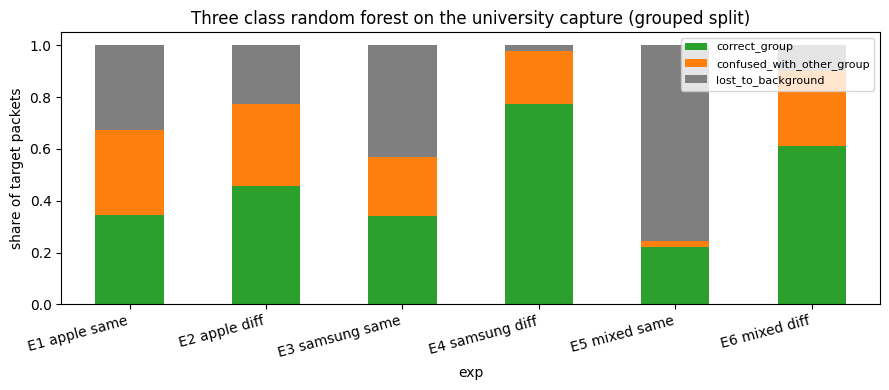

In [5]:
sub = h2[(h2['split'] == 'grouped') & (h2['frame'] == 'transfer')].set_index('exp')
ax = sub[['correct_group', 'confused_with_other_group', 'lost_to_background']].plot.bar(
    stacked=True, figsize=(9, 4), color=['tab:green', 'tab:orange', 'tab:grey'])
ax.set_ylabel('share of target packets')
ax.set_title('Three class random forest on the university capture (grouped split)')
ax.legend(loc='upper right', fontsize=8)
plt.xticks(rotation=15, ha='right'); plt.tight_layout()
plt.savefig(FIGURES / 'fig_h2_target_packet_outcome.pdf'); plt.show()

## 3. Confidence intervals (bootstrap over source addresses)

`MODELS` controls which learners are included. On the university capture all runs of one
experiment and label share the same packets, so they are bootstrapped together (paired). The
in domain test sets differ between the packet and the grouped split, so they are bootstrapped
separately.

In [6]:
N_BOOT = 1000
LABELS = ['multi', 'binary']
MODELS = ['random_forest', 'multi_layer_perceptron', 'stochastic_gradient_descent']
SPLITS = ['packet', 'grouped']
METRICS = ['macro_f1', 'mcc']

boot = {}      # (exp, label, frame, metric) -> DataFrame with one column per 'model|split'
ci_rows = []
for ei, e in enumerate(EXPS):
    for label in LABELS:
        # transfer: paired over all runs
        preds = {f'{mo}|{sp}': au.load_predictions(e, label, mo, sp, 'transfer') for mo in MODELS for sp in SPLITS}
        first = next(iter(preds.values()))
        for metric in METRICS:
            b = au.cluster_bootstrap(first['source'], first['y_true'], {k: v['y_pred'] for k, v in preds.items()},
                                     metric, N_BOOT, seed=100 + ei)
            boot[(e, label, 'transfer', metric)] = b
        # in domain: one bootstrap per run
        for mo in MODELS:
            for sp in SPLITS:
                p = au.load_predictions(e, label, mo, sp, 'indomain')
                for metric in METRICS:
                    b = au.cluster_bootstrap(p['source'], p['y_true'], {f'{mo}|{sp}': p['y_pred']},
                                             metric, N_BOOT, seed=200 + ei)
                    boot.setdefault((e, label, 'indomain', metric), pd.DataFrame({'replicate': b['replicate']}))
                    boot[(e, label, 'indomain', metric)][f'{mo}|{sp}'] = b[f'{mo}|{sp}']

for (e, label, frame, metric), b in boot.items():
    for run in [c for c in b.columns if c != 'replicate']:
        mo, sp = run.split('|')
        lo, hi = au.ci(b[run])
        ci_rows.append(dict(exp=au.exp_name(e), label=label, frame=frame, metric=metric, model=mo, split=sp,
                            boot_mean=b[run].mean(), ci_low=lo, ci_high=hi))
cis = pd.DataFrame(ci_rows)
point = (m.assign(model=m['model'].map(au.slug))
          .melt(id_vars=['exp', 'label', 'model', 'split', 'frame'], value_vars=METRICS,
                var_name='metric', value_name='point'))
cis = cis.merge(point, on=['exp', 'label', 'model', 'split', 'frame', 'metric'], how='left')
cis.to_csv(RESULTS / 'confidence_intervals.csv', index=False)
cis[(cis['model'] == 'random_forest') & (cis['metric'] == 'macro_f1')].round(3)

,exp,label,frame,metric,model,split,boot_mean,ci_low,ci_high,point
0,E1 apple same,multi,transfer,macro_f1,random_forest,packet,0.398,0.373,0.423,0.398
1,E1 apple same,multi,transfer,macro_f1,random_forest,grouped,0.383,0.359,0.405,0.383
12,E1 apple same,multi,indomain,macro_f1,random_forest,packet,0.941,0.923,0.958,0.941
13,E1 apple same,multi,indomain,macro_f1,random_forest,grouped,0.908,0.863,0.948,0.908
24,E1 apple same,binary,transfer,macro_f1,random_forest,packet,0.638,0.603,0.673,0.638
25,E1 apple same,binary,transfer,macro_f1,random_forest,grouped,0.640,0.611,0.670,0.640
36,E1 apple same,binary,indomain,macro_f1,random_forest,packet,0.999,0.997,1.000,0.999
37,E1 apple same,binary,indomain,macro_f1,random_forest,grouped,0.999,0.997,1.000,0.999
48,E2 apple diff,multi,transfer,macro_f1,random_forest,packet,0.500,0.436,0.559,0.502
49,E2 apple diff,multi,transfer,macro_f1,random_forest,grouped,0.488,0.426,0.551,0.490


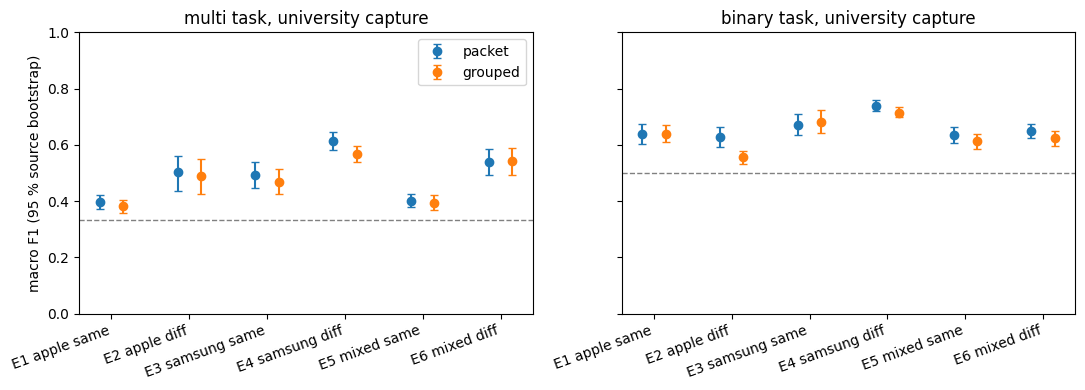

In [7]:
# Transfer macro F1 of the random forest with 95 % intervals
sub = cis[(cis['model'] == 'random_forest') & (cis['metric'] == 'macro_f1') & (cis['frame'] == 'transfer')]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, label in zip(axes, LABELS):
    s = sub[sub['label'] == label]
    for k, sp in enumerate(SPLITS):
        q = s[s['split'] == sp]
        x = np.arange(len(q)) + (k - 0.5) * 0.3
        ax.errorbar(x, q['point'], yerr=[q['point'] - q['ci_low'], q['ci_high'] - q['point']],
                    fmt='o', capsize=3, label=sp)
    ax.set_xticks(np.arange(len(q))); ax.set_xticklabels(q['exp'], rotation=20, ha='right')
    ax.axhline(1 / 3 if label == 'multi' else 0.5, ls='--', lw=1, color='grey')
    ax.set_title(f'{label} task, university capture'); ax.set_ylim(0, 1)
axes[0].set_ylabel('macro F1 (95 % source bootstrap)'); axes[0].legend()
plt.tight_layout(); plt.savefig(FIGURES / 'fig_ci_transfer_macro_f1.pdf'); plt.show()

## 4. Significance tests

* **H3** packet against grouped split: on the university capture the two runs are paired (same
  packets): paired source bootstrap and McNemar. In domain the test sets differ: unpaired.
* **H4** in domain against transfer: unpaired (different test sets).
* **H1** same against different distance (E1/E2, E3/E4, E5/E6): unpaired.
* **Models**: random forest against MLP and SGD on the university capture: paired.

All p values of one hypothesis family are Holm corrected. Primary metric: macro F1.

In [8]:
METRIC = 'macro_f1'
tests = []

def add(hyp, exp, label, frame, a, b, res):
    tests.append(dict(hypothesis=hyp, exp=exp, label=label, frame=frame, a=a, b=b, **res))

for e in EXPS:
    for label in LABELS:
        bt = boot[(e, label, 'transfer', METRIC)]
        bi = boot[(e, label, 'indomain', METRIC)]
        # H3, transfer, paired
        res = au.paired_bootstrap_test(bt, 'random_forest|packet', 'random_forest|grouped')
        pa = au.load_predictions(e, label, 'random_forest', 'packet', 'transfer', with_meta=False)
        pg = au.load_predictions(e, label, 'random_forest', 'grouped', 'transfer', with_meta=False)
        res.update(au.mcnemar(pa['y_true'], pa['y_pred'], pg['y_pred']))
        add('H3', au.exp_name(e), label, 'transfer', 'packet', 'grouped', res)
        # H3, in domain, unpaired
        add('H3', au.exp_name(e), label, 'indomain', 'packet', 'grouped',
            au.unpaired_bootstrap_test(bi['random_forest|packet'], bi['random_forest|grouped']))
        # H4, grouped split
        add('H4', au.exp_name(e), label, 'indomain-transfer', 'indomain', 'transfer',
            au.unpaired_bootstrap_test(bi['random_forest|grouped'], bt['random_forest|grouped']))
        # models, transfer, paired
        for other in [mo for mo in MODELS if mo != 'random_forest']:
            for sp in SPLITS:
                res = au.paired_bootstrap_test(bt, f'random_forest|{sp}', f'{other}|{sp}')
                add('models', au.exp_name(e), label, f'transfer/{sp}', 'random_forest', other, res)

# H1: same against different distance
for same, diff in au.DISTANCE_PAIRS:
    if same not in EXPS or diff not in EXPS:
        continue
    for label in LABELS:
        for frame in ['transfer', 'indomain']:
            for sp in SPLITS:
                add('H1', f'{au.exp_name(same)} / {au.exp_name(diff)}', label, f'{frame}/{sp}', 'same', 'diff',
                    au.unpaired_bootstrap_test(boot[(same, label, frame, METRIC)][f'random_forest|{sp}'],
                                               boot[(diff, label, frame, METRIC)][f'random_forest|{sp}']))

tests = pd.DataFrame(tests)
tests['p_holm'] = np.nan
for hyp, idx in tests.groupby('hypothesis').groups.items():
    tests.loc[idx, 'p_holm'] = au.holm(tests.loc[idx, 'p_boot'])
tests['significant_5pct'] = tests['p_holm'] < 0.05
tests.to_csv(RESULTS / 'significance_tests.csv', index=False)
tests.round(4)

,hypothesis,exp,label,frame,a,b,diff_mean,ci_low,ci_high,p_boot,a_only_correct,b_only_correct,chi2,p_mcnemar,p_holm,significant_5pct
0,H3,E1 apple same,multi,transfer,packet,grouped,0.0155,0.0110,0.0208,0.000,57106.0,10609.0,31926.1318,0.0,0.000,True
1,H3,E1 apple same,multi,indomain,packet,grouped,0.0328,-0.0120,0.0817,0.176,NaN,NaN,NaN,NaN,1.000,False
2,H4,E1 apple same,multi,indomain-transfer,indomain,transfer,0.5254,0.4747,0.5718,0.000,NaN,NaN,NaN,NaN,0.000,True
3,models,E1 apple same,multi,transfer/packet,random_forest,multi_layer_perceptron,0.0580,0.0355,0.0785,0.000,NaN,NaN,NaN,NaN,0.000,True
4,models,E1 apple same,multi,transfer/grouped,random_forest,multi_layer_perceptron,0.0119,-0.0111,0.0364,0.348,NaN,NaN,NaN,NaN,1.000,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,H1,E5 mixed same / E6 mixed diff,multi,indomain/grouped,same,diff,-0.0094,-0.0658,0.0439,0.744,NaN,NaN,NaN,NaN,1.000,False
104,H1,E5 mixed same / E6 mixed diff,binary,transfer/packet,same,diff,-0.0124,-0.0504,0.0242,0.496,NaN,NaN,NaN,NaN,1.000,False
105,H1,E5 mixed same / E6 mixed diff,binary,transfer/grouped,same,diff,-0.0094,-0.0452,0.0278,0.616,NaN,NaN,NaN,NaN,1.000,False
106,H1,E5 mixed same / E6 mixed diff,binary,indomain/packet,same,diff,0.0150,-0.0000,0.0307,0.052,NaN,NaN,NaN,NaN,0.728,False


## 5. Variability over the two hour blocks (optional, retrains)

Leave one block out with the random forest: train on all but one two hour block, test on the
left out block (a later or earlier session of the same campaign) and on the university
capture. This gives one score per block, so the spread between blocks can be reported (the
design argues for five independent recording units).

Runtime: one random forest fit per block, label and experiment (about 1 to 3 minutes each).

In [9]:
RUN_BLOCK_CV = True
BLOCK_LABELS = ['group_label_multi', 'group_label']

if RUN_BLOCK_CV:
    from sklearn.metrics import f1_score, matthews_corrcoef
    block_rows = []
    for e in EXPS:
        tr = au.load_frame(e, 'train')
        ev = au.load_frame(e, 'eval')
        feats = au.feature_columns(tr)
        for label in BLOCK_LABELS:
            for b in sorted(tr['block'].unique()):
                held = tr['block'] == b
                model = au.make_random_forest().fit(tr.loc[~held, feats], tr.loc[~held, label])
                for frame, df in [('left out block', tr[held]), ('transfer', ev)]:
                    y = model.predict(df[feats])
                    block_rows.append(dict(exp=au.exp_name(e), label=label, block=int(b), frame=frame,
                                           macro_f1=f1_score(df[label], y, average='macro', zero_division=0),
                                           mcc=matthews_corrcoef(df[label], y)))
                print(e, label, 'block', b, 'done')
            del model
    blocks = pd.DataFrame(block_rows)
    blocks.to_csv(RESULTS / 'block_variability.csv', index=False)
    display(blocks.groupby(['label', 'frame', 'exp'])[['macro_f1', 'mcc']].agg(['mean', 'std', 'min', 'max']).round(3))

E1_apple_same group_label_multi block 0 done


E1_apple_same group_label_multi block 1 done


E1_apple_same group_label_multi block 2 done


E1_apple_same group_label_multi block 3 done


E1_apple_same group_label_multi block 4 done


E1_apple_same group_label block 0 done


... (43 outputs left out)

E6_mixed_diff group_label block 0 done


E6_mixed_diff group_label block 1 done


E6_mixed_diff group_label block 2 done


macro_f1                \
                                                     mean    std    min   
label             frame          exp                                      
group_label       left out block E1 apple same      0.999  0.002  0.995   
                                 E2 apple diff      0.997  0.003  0.993   
                                 E3 samsung same    0.992  0.012  0.971   
                                 E4 samsung diff    0.998  0.001  0.997   
                                 E5 mixed same      0.926  0.011  0.913   
                                 E6 mixed diff      0.924  0.021  0.900   
                  transfer       E1 apple same      0.633  0.012  0.620   
                                 E2 apple diff      0.608  0.009  0.601   
                                 E3 samsung same    0.667  0.012  0.651   
                                 E4 samsung diff    0.774  0.043  0.721   
                                 E5 mixed same      0.646  0.019  0.633   
                                 E6 mixed diff      0.646  0.042  0.605   
group_label_multi left out block E1 apple same      0.897  0.018  0.871   
                                 E2 apple diff      0.913  0.023  0.879   
                                 E3 samsung same    0.982  0.022  0.942   
                                 E4 samsung diff    0.993  0.002  0.991   
                                 E5 mixed same      0.921  0.011  0.911   
                                 E6 mixed diff      0.905  0.048  0.850   
                  transfer       E1 apple same      0.412  0.013  0.399   
                                 E2 apple diff      0.468  0.036  0.406   
                                 E3 samsung same    0.479  0.018  0.467   
                                 E4 samsung diff    0.608  0.036  0.575   
                                 E5 mixed same      0.440  0.065  0.365   
                                 E6 mixed diff      0.515  0.024  0.488   

                                                           mcc                \
                                                    max   mean    std    min   
label             frame          exp                                           
group_label       left out block E1 apple same    1.000  0.998  0.005  0.989   
                                 E2 apple diff    0.999  0.993  0.006  0.986   
                                 E3 samsung same  0.998  0.985  0.023  0.943   
                                 E4 samsung diff  0.999  0.996  0.002  0.994   
                                 E5 mixed same    0.935  0.852  0.023  0.827   
                                 E6 mixed diff    0.937  0.854  0.034  0.815   
                  transfer       E1 apple same    0.649  0.337  0.016  0.319   
                                 E2 apple diff    0.622  0.308  0.014  0.292   
                                 E3 samsung same  0.681  0.381  0.010  0.370   
                                 E4 samsung diff  0.816  0.615  0.062  0.539   
                                 E5 mixed same    0.668  0.386  0.035  0.354   
                                 E6 mixed diff    0.689  0.398  0.058  0.342   
group_label_multi left out block E1 apple same    0.917  0.882  0.024  0.842   
                                 E2 apple diff    0.941  0.874  0.026  0.836   
                                 E3 samsung same  0.992  0.972  0.041  0.899   
                                 E4 samsung diff  0.995  0.991  0.003  0.986   
                                 E5 mixed same    0.933  0.882  0.018  0.866   
                                 E6 mixed diff    0.935  0.864  0.062  0.792   
                  transfer       E1 apple same    0.432  0.266  0.020  0.236   
                                 E2 apple diff    0.490  0.295  0.044  0.219   
                                 E3 samsung same  0.510  0.311  0.027  0.291   
                                 E4 samsung diff  0.670  0.478  0.081  0.395   
                       